# Music Genre Tagging — Part 1: Data Exploration

**Client question:** A music streaming service wants to auto-tag the genre of new songs.
They want to know: *how accurate would it be, and is it reliable for every genre, not just the common ones?*

**Data:** 8,111 songs from the Free Music Archive (FMA) across 5 genres, each with 237 numeric features.

This notebook covers:
1. Loading the data correctly and naming the columns
2. Data quality checks
3. Genre balance and why plain accuracy would mislead
4. How genres differ in sound

Modelling follows in Part 2.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path("..")
IMAGES = ROOT / "images"; IMAGES.mkdir(exist_ok=True)
PROCESSED = ROOT / "data" / "processed"; PROCESSED.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, AQUA, YELLOW, VIOLET, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#c3c2b7"
INK, INK_2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": GREY, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e8e7e3", "axes.axisbelow": True,
})

## 1. Load the data

The file has **no header row**. Reading it with default settings would silently treat the first song as column names and drop it,
so `header=None` is essential.

**Naming the columns.** The 237 features follow the FMA "Echonest" feature set (Defferrard et al., 2017).
The value ranges confirm the mapping: the first 8 are audio descriptors between 0 and 1 (plus tempo in BPM), then 5 artist/song popularity scores, then 224 low-level temporal audio features.

In [2]:
audio = ["acousticness", "danceability", "energy", "instrumentalness",
         "liveness", "speechiness", "tempo", "valence"]
social = ["artist_discovery", "artist_familiarity", "artist_hotttnesss",
          "song_currency", "song_hotttnesss"]
temporal = [f"temporal_{i:03d}" for i in range(1, 225)]
columns = ["genre"] + audio + social + temporal

music = pd.read_csv(ROOT / "data" / "raw" / "music.csv", header=None, names=columns)
music["genre"] = music["genre"].str.strip()   # some labels have leading spaces
print(music.shape)
music[["genre"] + audio + social].head()

(8111, 238)


,genre,acousticness,danceability,energy,instrumentalness,liveness,speechiness,tempo,valence,artist_discovery,artist_familiarity,artist_hotttnesss,song_currency,song_hotttnesss
0,Hip-Hop,0.416675,0.675894,0.634476,0.010628,0.177647,0.159310,165.922,0.576661,0.388990,0.386740,0.40637,0.00000,0.00000
1,Hip-Hop,0.374408,0.528643,0.817461,0.001851,0.105880,0.461818,126.957,0.269240,0.388990,0.386740,0.40637,0.00000,0.00000
2,Hip-Hop,0.043567,0.745566,0.701470,0.000697,0.373143,0.124595,100.260,0.621661,0.388990,0.386740,0.40637,0.00000,0.00000
3,Hip-Hop,0.452217,0.513238,0.560410,0.019443,0.096567,0.525519,114.290,0.894072,0.388990,0.386740,0.40637,0.00000,0.00000
4,Folk,0.106550,0.260911,0.607067,0.835087,0.223676,0.030569,196.961,0.160267,0.388923,0.330784,0.40630,0.00025,0.03855


## 2. Data quality checks

In [3]:
checks = {
    "Rows (songs)": len(music),
    "Feature columns": music.shape[1] - 1,
    "Missing values": int(music.isna().sum().sum()),
    "Duplicate rows": int(music.duplicated().sum()),
    "Non-numeric feature columns": int((music.drop(columns="genre").dtypes == object).sum()),
}
pd.Series(checks, name="value").to_frame()

,value
Rows (songs),8111
Feature columns,237
Missing values,0
Duplicate rows,0
Non-numeric feature columns,0


In [4]:
music[audio + social].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
acousticness,8111.0,0.499,0.382,0.000,0.077,0.521,0.900,0.996
danceability,8111.0,0.469,0.194,0.051,0.320,0.459,0.614,0.967
energy,8111.0,0.568,0.277,0.000,0.366,0.587,0.807,1.000
instrumentalness,8111.0,0.655,0.354,0.000,0.401,0.845,0.920,0.998
liveness,8111.0,0.182,0.150,0.025,0.102,0.118,0.201,0.971
speechiness,8111.0,0.100,0.135,0.023,0.037,0.050,0.088,0.966
tempo,8111.0,123.923,35.122,12.753,95.953,121.017,147.564,250.059
valence,8111.0,0.428,0.275,0.000,0.187,0.403,0.649,1.000
artist_discovery,8111.0,0.324,0.112,0.000,0.258,0.334,0.413,0.580
artist_familiarity,8111.0,0.298,0.129,0.000,0.216,0.291,0.373,0.803


**Findings**
- All 8,111 songs are present, with no missing values or duplicates, and every feature is numeric. The data is clean.
- Genre labels had stray leading spaces (e.g. `" Rock"`), which would have split one genre into two. These are fixed above.
- `song_currency` and `song_hotttnesss` are almost always zero, so they carry little information. I keep them for now and let the model decide.
- Features sit on very different scales (tempo up to ~250 vs. 0–1 for most others), which matters for distance-based models but not for tree-based ones.

## 3. Genre balance: why accuracy would mislead

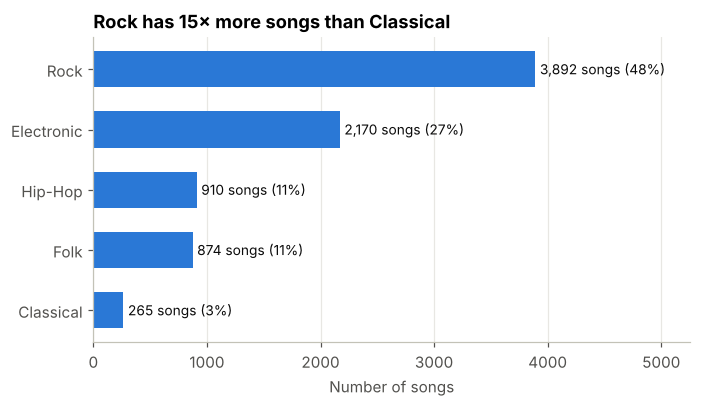

A model that always guesses 'Rock' would already be 48% accurate,
while getting every other genre wrong.


In [5]:
counts = music["genre"].value_counts()
share = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.barh(counts.index[::-1], counts.values[::-1], color=BLUE, height=0.6)
for b, n, s in zip(bars, counts.values[::-1], share.values[::-1]):
    ax.text(b.get_width() + 40, b.get_y() + b.get_height() / 2, f"{n:,} songs ({s:.0f}%)",
            va="center", fontsize=9, color=INK)
ax.set_xlim(0, counts.max() * 1.35)
ax.set_xlabel("Number of songs")
ax.grid(axis="y", visible=False)
ax.set_title("Rock has 15× more songs than Classical")
fig.savefig(IMAGES / "genre_balance.png")
plt.show()

print(f"A model that always guesses 'Rock' would already be {share.max():.0f}% accurate,")
print("while getting every other genre wrong.")

**Why this matters for the client.** Nearly half the songs are Rock. A useless model that labels everything "Rock" would score about **48% accuracy**
while failing completely on the other four genres. The client said performance must be good **for all genres**, so in Part 2 I'll judge models on:
- **Macro-F1**, which averages the score across genres so each genre counts equally
- **Per-genre recall**, which answers "of all the real Folk songs, how many did we tag correctly?"

## 4. How do genres differ in sound?

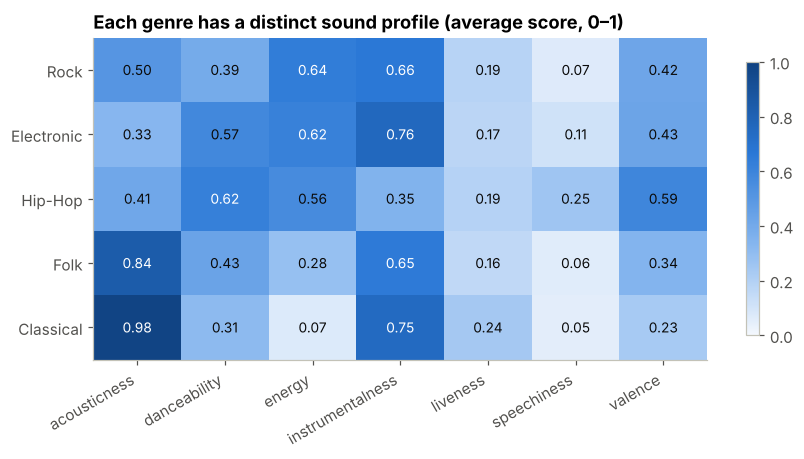

,acousticness,danceability,energy,instrumentalness,liveness,speechiness,valence
genre,,,,,,,
Rock,0.50,0.39,0.64,0.66,0.19,0.07,0.42
Electronic,0.33,0.57,0.62,0.76,0.17,0.11,0.43
Hip-Hop,0.41,0.62,0.56,0.35,0.19,0.25,0.59
Folk,0.84,0.43,0.28,0.65,0.16,0.06,0.34
Classical,0.98,0.31,0.07,0.75,0.24,0.05,0.23


In [6]:
profile = music.groupby("genre")[[a for a in audio if a != "tempo"]].mean()
order = counts.index.tolist()
profile = profile.loc[order]

fig, ax = plt.subplots(figsize=(9, 3.8))
from matplotlib.colors import LinearSegmentedColormap
seq = LinearSegmentedColormap.from_list("blue", ["#f4f8fd", "#86b6ef", "#2a78d6", "#104281"])
im = ax.imshow(profile.values, cmap=seq, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(profile.shape[1]), profile.columns, rotation=30, ha="right")
ax.set_yticks(range(len(order)), order)
for i in range(profile.shape[0]):
    for j in range(profile.shape[1]):
        v = profile.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="white" if v > 0.6 else INK)
ax.grid(False)
ax.set_title("Each genre has a distinct sound profile (average score, 0–1)")
fig.colorbar(im, ax=ax, shrink=0.85)
fig.savefig(IMAGES / "genre_sound_profiles.png")
plt.show()
profile.round(2)

**What stands out**
- **Classical** is almost purely acoustic (0.98) with very low energy (0.07) and the lowest valence (musical "positivity"). It should be easy to identify despite having the fewest songs.
- **Hip-Hop** stands out on speechiness (0.25, more than double any other genre, reflecting rap vocals), danceability and valence. It is also the least instrumental.
- **Electronic** is the most instrumental and the least acoustic, which separates it clearly from Classical.
- **Folk** sits between Rock and Classical: acoustic like Classical, but with more energy.
- **Rock** is in the middle on most features, with energy almost identical to Electronic. Middle-of-the-road profiles are where a model is most likely to confuse genres, which Part 2 will test.

**Next (Part 2):** baseline models, handling the imbalance, the tuned model, and a per-genre reliability report for the client.

In [7]:
music.to_csv(PROCESSED / "music_named.csv", index=False)
print("Saved data with named columns to", PROCESSED / "music_named.csv")

Saved data with named columns to ../data/processed/music_named.csv
